<a href="https://colab.research.google.com/github/Malimige/Assignment_02_Abstract_Factory/blob/main/Week_3_Pair_Programming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pair Programming: Heart Disease Classification with an MLP

1. Why would a linear output be less suitable than sigmoid for this target?
- A sigmoid produces a value between 0 and 1 which is suitable for binary classification.
2. Why is an error measured in continuous-value units not the natural evaluation metric for this 0/1 target?
- Because the model predicts two classes, 0 and 1, rather than a continuous numerical value. Classification accuracy is more appropriate for evaluating correct class predictions.
3. Does a predicted probability of 0.8 guarantee that the patient has heart disease?
- No. It only means the model estimates an 80% probability of class 1. It does not guarantee that the patient has heart disease.

## 2. Load and Explore the Dataset

In [1]:
# If the required packages are not installed, install them first.
# In a separate Colab cell, only if imports are missing:
# %pip install numpy pandas matplotlib scikit-learn keras tensorflow

import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import Sequential, Input
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)

DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/heart.csv"
print("Keras backend:", keras.config.backend())


Keras backend: tensorflow


In [2]:
heart_data = pd.read_csv(DATA_URL)

print("First five rows:")
print(heart_data.head())

print("\nDataset shape:")
print(heart_data.shape)

print("\nColumn names:")
print(heart_data.columns)

print("\nMissing values:")
print(heart_data.isna().sum())

print("\nTarget values:")
print(heart_data["target"].value_counts())

First five rows:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

   ca        thal  target  
0   0       fixed       0  
1   3      normal       1  
2   2  reversible       0  
3   0      normal       0  
4   0      normal       0  

Dataset shape:
(303, 14)

Column names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0


### Why is this a binary classification task?

This is a binary classification task because the target has only two possible classes, 0 and 1. The model predicts whether a patient belongs to class 0 or class 1.



### Section 2 Checkpoint

- Dataset: 303 rows and 14 columns
- Numerical features: 6
- Categorical features: 7
- Target labels: 0 and 1
- Class 0: 220 records
- Class 1: 83 records
- Missing values: None

The task is binary classification because the target contains two classes, 0 and 1.


## 3. Separate Features from the Target; Reserve Held-out Data

In [3]:
X = heart_data.drop(columns=["target"])
y = heart_data["target"]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2,
    random_state=42, stratify=y_train_val
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (193, 13)
X_val: (49, 13)
X_test: (61, 13)
y_train: (193,)
y_val: (49,)
y_test: (61,)



### Section 3 Discussion

**1. Why are the proportions approximately 64% training, 16% validation, and 20% test?**

First, 20% is reserved for testing. From the remaining 80%, another 20% is used for validation. This gives 64% training, 16% validation, and 20% testing.

**2. Why must the scaler learn nothing from validation or test rows?**

To prevent data leakage and ensure a fair evaluation of the model.

**3. Why should the final model not be selected using test accuracy?**

Because the test data should only be used for the final evaluation. Model selection must be based on validation results.


## 4. Establish a Majority-Class Baseline

In [4]:
class_counts = y_train.value_counts()
class_proportions = y_train.value_counts(normalize=True)

majority_class = class_counts.idxmax()
majority_proportion = class_proportions.max()

print("Training class counts:")
print(class_counts)

print("\nTraining class proportions:")
print(class_proportions)

print("\nMajority class:", majority_class)
print("Majority-class baseline:", majority_proportion)

Training class counts:
target
0    140
1     53
Name: count, dtype: int64

Training class proportions:
target
0    0.725389
1    0.274611
Name: proportion, dtype: float64

Majority class: 0
Majority-class baseline: 0.7253886010362695


### Section 4 Discussion

No, a model with 70% accuracy is not necessarily better. Its accuracy should be compared with the majority-class baseline. If the baseline accuracy is higher than 70%, the model is not better.

## 5. Encode Categorical Inputs

In [5]:
categorical_variables = ["sex", "cp", "fbs", "restecg", "exang", "ca", "thal"]
numerics = ["age", "trestbps", "chol", "thalach", "oldpeak", "slope"]

X_train_encoded = pd.get_dummies(
    X_train, columns=categorical_variables, dtype=np.float32
)

# Apply the same training-derived set of columns to held-out data.
def encode_like_training(frame):
    encoded = pd.get_dummies(
        frame, columns=categorical_variables, dtype=np.float32
    )
    return encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

X_val_encoded = encode_like_training(X_val)
X_test_encoded = encode_like_training(X_test)

In [6]:
print("Training encoded shape:", X_train_encoded.shape)
print("Validation encoded shape:", X_val_encoded.shape)
print("Test encoded shape:", X_test_encoded.shape)

print("\nEncoded columns:")
print(X_train_encoded.columns)

print("\nValidation columns match training:",
      X_val_encoded.columns.equals(X_train_encoded.columns))

print("Test columns match training:",
      X_test_encoded.columns.equals(X_train_encoded.columns))

Training encoded shape: (193, 29)
Validation encoded shape: (49, 29)
Test encoded shape: (61, 29)

Encoded columns:
Index(['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'slope', 'sex_0',
       'sex_1', 'cp_0', 'cp_1', 'cp_2', 'cp_3', 'cp_4', 'fbs_0', 'fbs_1',
       'restecg_0', 'restecg_1', 'restecg_2', 'exang_0', 'exang_1', 'ca_0',
       'ca_1', 'ca_2', 'ca_3', 'thal_1', 'thal_2', 'thal_fixed', 'thal_normal',
       'thal_reversible'],
      dtype='object')

Validation columns match training: True
Test columns match training: True


### Section 5 Discussion

**1. Why can the number of model inputs exceed 13?**

One-hot encoding converts categorical features into multiple binary columns, increasing the number of inputs.

**2. Why is age not one-hot encoded?**

Age is a numerical feature with meaningful numerical values, so it does not need one-hot encoding.

**3. Why must the encoding rule be kept with the model?**

New data must use the same encoded columns and column order as the training data to produce correct model inputs.


## 6. Standardize Numerical Features and Prepare Model Inputs

In [7]:
scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_val_scaled = X_val_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numerics] = scaler.fit_transform(X_train_encoded[numerics])
X_val_scaled[numerics] = scaler.transform(X_val_encoded[numerics])
X_test_scaled[numerics] = scaler.transform(X_test_encoded[numerics])

train_X = X_train_scaled.to_numpy(dtype="float32")
val_X = X_val_scaled.to_numpy(dtype="float32")
test_X = X_test_scaled.to_numpy(dtype="float32")

train_y = y_train.to_numpy(dtype="float32")
val_y = y_val.to_numpy(dtype="float32")
test_y = y_test.to_numpy(dtype="float32")

print("Training:", train_X.shape, train_y.shape)
print("Validation:", val_X.shape, val_y.shape)
print("Testing:", test_X.shape, test_y.shape)

print("\nNaN values:")
print("Training:", np.isnan(train_X).sum())
print("Validation:", np.isnan(val_X).sum())
print("Testing:", np.isnan(test_X).sum())

Training: (193, 29) (193,)
Validation: (49, 29) (49,)
Testing: (61, 29) (61,)

NaN values:
Training: 0
Validation: 0
Testing: 0


### Section 6 Checkpoint

All three datasets have 29 input features after encoding and scaling.

The scaler was fitted only on the training numerical features to prevent data leakage.

The validation and test datasets were transformed using the same training-fitted scaler.

The target column is not included in the input features.

## 7. Build the MLP: One Hidden Layer, One Sigmoid Output

In [8]:
keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(train_X.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

### Parameter Calculation

Hidden layer: (29 × 16) + 16 = 480 parameters

Output layer: (16 × 1) + 1 = 17 parameters

Total trainable parameters = 497

### Section 7 Discussion

**1. Why does the output layer have one neuron instead of two?**

Because this is binary classification. One sigmoid neuron can predict the probability of class 1.

**2. What would change if the model predicted a continuous value?**

A linear output would be used instead of sigmoid, and a regression loss function such as mean squared error.

## 8. Compile the Classification Model

In [10]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### Section 8 Discussion

**1. What does each compile() argument control?**

- Optimizer: Adam updates the model weights during training.
- Loss: Binary cross-entropy measures the prediction error.
- Metrics: Accuracy measures the proportion of correct predictions.

**2. If the true class is 1, should the loss be lower for a prediction of 0.9 or 0.1?**

The loss should be lower for 0.9 because it is closer to the correct class of 1.

**3. Does an optimizer calculate gradients, apply updates, or both?**

Backpropagation calculates the gradients, and the optimizer uses them to update the model weights.

## 9. Train the Baseline and Observe Learning Curves

In [11]:
history = model.fit(
    train_X,
    train_y,
    epochs=300,
    batch_size=32,
    validation_data=(val_X, val_y),
    verbose=0
)

In [12]:
print("History keys:", history.history.keys())

print("Final training BCE:", history.history["loss"][-1])
print("Final validation BCE:", history.history["val_loss"][-1])

print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

History keys: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])
Final training BCE: 0.10617838054895401
Final validation BCE: 0.23675431311130524
Final training accuracy: 0.9740932583808899
Final validation accuracy: 0.8775510191917419


### Training and Validation Loss

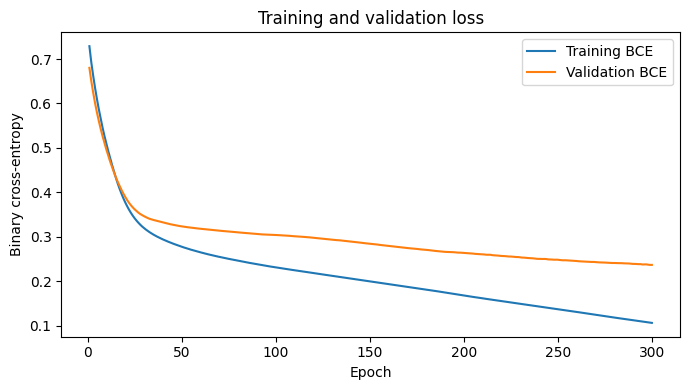

In [13]:
loss_values = history.history["loss"]
val_loss_values = history.history["val_loss"]
epoch_numbers = range(1, len(loss_values) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, loss_values, label="Training BCE")
plt.plot(epoch_numbers, val_loss_values, label="Validation BCE")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

### Training and Validation Accuracy

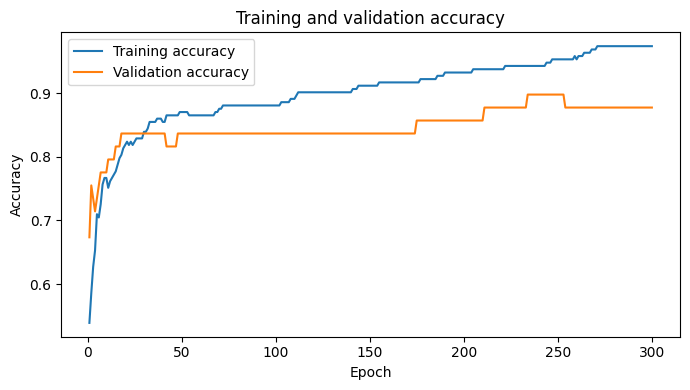

In [14]:
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
epoch_numbers = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_accuracy, label="Training accuracy")
plt.plot(epoch_numbers, val_accuracy, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.tight_layout()
plt.show()


### Section 9 Discussion

**1. Do training and validation loss follow the same trend?**

Yes. Both losses decrease during training, but training loss decreases faster than validation loss.

**2. Is there an interval where training loss decreases while validation loss increases? What might this suggest?**

No clear interval is visible. Both losses generally decrease, although the gap between them increases. This may suggest some overfitting.

**3. Why is one noisy validation epoch not enough to prove overfitting?**

Because validation results can fluctuate. The overall trend should be observed across several epochs.

**4. Can validation accuracy be high while validation BCE is worsening? What is each metric measuring?**

Yes. Accuracy measures the percentage of correct class predictions, while BCE measures the error in predicted probabilities.


## 10. Pair Challenge: Change One Thing, Then Choose a Model


### Prediction

Reducing training from 300 to 100 epochs may result in a higher validation loss because the model has fewer epochs to learn.


In [15]:
keras.utils.set_random_seed(42)

candidate_model = Sequential([
    Input(shape=(train_X.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

candidate_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

candidate_history = candidate_model.fit(
    train_X,
    train_y,
    epochs=100,
    batch_size=32,
    validation_data=(val_X, val_y),
    verbose=0
)

In [16]:

print("Baseline validation BCE:", history.history["val_loss"][-1])
print("Baseline validation accuracy:", history.history["val_accuracy"][-1])

print("Candidate validation BCE:", candidate_history.history["val_loss"][-1])
print("Candidate validation accuracy:", candidate_history.history["val_accuracy"][-1])


Baseline validation BCE: 0.23675431311130524
Baseline validation accuracy: 0.8775510191917419
Candidate validation BCE: 0.30398938059806824
Candidate validation accuracy: 0.8367347121238708



### Model Comparison

| Model | Architecture / Epochs | Final Validation BCE | Final Validation Accuracy | Observation |
|---|---|---|---|---|
| Baseline | 16 ReLU → 1 sigmoid; 300 epochs | 0.2368 | 87.76% | Lower validation loss |
| Candidate | 16 ReLU → 1 sigmoid; 100 epochs | 0.3040 | 83.67% | Higher validation loss |

The baseline model was selected because it achieved a lower final validation BCE than the candidate model.


In [17]:

final_model = model

print("Selected model: Baseline MLP (300 epochs)")


Selected model: Baseline MLP (300 epochs)



### Section 10 Discussion

**1. Can longer training produce lower training loss but worse validation loss?**

Yes. Longer training can reduce training loss while increasing validation loss due to overfitting.

**2. Does a single split prove which architecture is universally best?**

No. Results can change with different data splits. A single split does not prove that one model is always better.

### Model Selection

The baseline model was selected because it achieved a lower final validation BCE (0.2368) than the candidate model (0.3040).

The baseline also achieved higher validation accuracy (87.76%) compared with the candidate (83.67%).



## 11. Final Evaluation: Test Data and the Baseline


In [18]:
test_loss, test_accuracy = final_model.evaluate(
    test_X, test_y, verbose=0
)

print("Test BCE:", test_loss)
print("Test accuracy:", test_accuracy)

Test BCE: 0.5868663191795349
Test accuracy: 0.7540983557701111


In [19]:
baseline_test_accuracy = np.mean(test_y == majority_class)

print("Majority-class test accuracy:", baseline_test_accuracy)
print("MLP test accuracy:", test_accuracy)

print("MLP improvement over baseline:", test_accuracy - baseline_test_accuracy)

Majority-class test accuracy: 0.7213114754098361
MLP test accuracy: 0.7540983557701111
MLP improvement over baseline: 0.032786880360274995



### Section 11 Discussion

**1. Why can accuracy alone hide poor performance on one class?**

Accuracy measures the overall percentage of correct predictions. A model may achieve high accuracy by predicting the majority class correctly while performing poorly on the minority class.



### Section 11 Checkpoint

The baseline MLP trained for 300 epochs was selected using validation BCE.

- Test BCE: 0.5869
- Test accuracy: 75.41%
- Majority-class test accuracy: 72.13%

The selected MLP improved test accuracy by 3.28 percentage points compared with the majority-class baseline.

However, accuracy alone does not show how well the model predicts each class. The dataset is also small, which limits the reliability of the evaluation.



## 12. Inference


In [20]:

probabilities = final_model.predict(test_X[:5]).ravel()

predicted_labels = (probabilities >= 0.5).astype(int)

print("Predicted probabilities:", probabilities)
print("Predicted labels:", predicted_labels)
print("Actual labels:", test_y[:5])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
Predicted probabilities: [1.1274437e-02 4.7418885e-03 9.7289249e-02 7.2938874e-02 3.9462593e-06]
Predicted labels: [0 0 0 0 0]
Actual labels: [0. 0. 0. 0. 0.]



### Section 12 Discussion

**Why must future patient records use the same one-hot encoding and scaler?**

New data must use the same encoded columns, column order, and training-fitted scaler as the original training data. Otherwise, the model may receive incorrect inputs and produce unreliable predictions.



### Section 12 Checkpoint

The model predicted class 0 for all five test examples using a threshold of 0.5.

All five predictions matched the actual labels.

However, these five examples belong to class 0, so they do not show how well the model predicts class 1.



## 13. What Is Missing from the Model Evaluation?


In [21]:

from sklearn.metrics import precision_score, recall_score, f1_score

test_probabilities = final_model.predict(test_X).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)

precision = precision_score(test_y, test_predictions)
recall = recall_score(test_y, test_predictions)
f1 = f1_score(test_y, test_predictions)

print("Test accuracy:", test_accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step 
Test accuracy: 0.7540983557701111
Precision: 0.6666666666666666
Recall: 0.23529411764705882
F1-score: 0.34782608695652173



### Section 13 Discussion

**1. What important information is missing from accuracy alone?**

Accuracy does not show how many false positives and false negatives the model makes.

**2. What do precision, recall, and F1-score measure?**

- Precision measures how many predicted positive cases are actually positive.
- Recall measures how many actual positive cases are correctly identified.
- F1-score combines precision and recall.

**3. What do the results reveal beyond accuracy?**

The model achieved 75.41% accuracy and 66.67% precision, but recall was only 23.53%. This shows that the model misses many actual class-1 cases.

**4. Can a model have high accuracy but poor performance on the positive class?**

Yes. The model has 75.41% accuracy but only 23.53% recall, showing poor detection of the positive class.

**5. Which type of error could be especially important in this dataset?**

False negatives could be especially important because they represent actual class-1 cases incorrectly predicted as class 0.



### Section 13 Checkpoint

- Test accuracy: 75.41%
- Precision: 66.67%
- Recall: 23.53%
- F1-score: 34.78%

Accuracy alone could hide poor detection of the positive class. Although the model correctly classifies many examples overall, its low recall shows that it misses many actual class-1 cases.



## Exit Discussion

**1. How does binary classification differ from predicting a continuous value?**

Binary classification predicts one of two classes, while regression predicts a continuous numerical value.

**2. Which preprocessing operation must be fitted using training data only?**

StandardScaler must be fitted using only the training data to prevent data leakage.

**3. What do backpropagation, Adam, and binary cross-entropy each do?**

- Backpropagation calculates gradients.
- Adam updates model weights using those gradients.
- Binary cross-entropy measures prediction error for binary classification.

**4. Why can the final test score not be used to choose another architecture?**

Because the test set is reserved for final evaluation. Using it for model selection would make the evaluation less reliable.

**5. What must be saved alongside model weights for new predictions?**

The one-hot encoding column order and the training-fitted scaler must be saved to preprocess new data consistently.


## Final Reflection

In this activity, I learned how to build and evaluate an MLP for binary classification.

I prevented data leakage by fitting the scaler only on the training data. The learning curves showed a gap between training and validation performance, suggesting some overfitting.

The selected model achieved 75.41% test accuracy, but its recall was only 23.53%. This showed me that accuracy alone is not enough to evaluate a classification model because it can hide poor performance on the positive class.